# IMDB Movie Dataset Analysis – Minor Project

**Objective:** Analyze the IMDB Movie dataset using Python, Pandas, Matplotlib and Seaborn. This notebook includes additional analyses required for the minor project, including top-rated movies overall and top-rated movies in the Comedy genre.

**Student:** TANTAPUREDDY NITHIN  
**Branch:** CSE  


## 1. Project Overview
The project analyzes movie information such as title, genre, year, rating, votes, revenue and metascore. The assignment asks students to add similar analyses to the existing IMDB project, with examples including the top 10 rated Comedy movies and top 5 rated movies overall.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')


## 2. Load the Dataset
Upload `IMDB-Movie-Data.csv` to Google Colab, then update the path below if necessary.


In [ ]:
# Download the dataset automatically if it is not already available
from pathlib import Path
import urllib.request

DATA_URL = "https://raw.githubusercontent.com/laxmimerit/All-CSV-ML-Data-Files-Download/master/IMDB-Movie-Data.csv"
DATA_PATH = Path("IMDB-Movie-Data.csv")
if not DATA_PATH.exists():
    print("Downloading IMDB dataset...")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
data = pd.read_csv(DATA_PATH)
print("Dataset loaded:", data.shape)
display(data.head())


Download completed!
Dataset loaded successfully!
Number of rows: 1000
Number of columns: 12


,Rank,Title,Genre,Description,Director,Actors,Year,Runtime (Minutes),Rating,Votes,Revenue (Millions),Metascore
0,1,Guardians of the Galaxy,"Action,Adventure,Sci-Fi",A group of intergalactic criminals are forced ...,James Gunn,"Chris Pratt, Vin Diesel, Bradley Cooper, Zoe S...",2014,121,8.1,757074,333.13,76.0
1,2,Prometheus,"Adventure,Mystery,Sci-Fi","Following clues to the origin of mankind, a te...",Ridley Scott,"Noomi Rapace, Logan Marshall-Green, Michael Fa...",2012,124,7.0,485820,126.46,65.0
2,3,Split,"Horror,Thriller",Three girls are kidnapped by a man with a diag...,M. Night Shyamalan,"James McAvoy, Anya Taylor-Joy, Haley Lu Richar...",2016,117,7.3,157606,138.12,62.0
3,4,Sing,"Animation,Comedy,Family","In a city of humanoid animals, a hustling thea...",Christophe Lourdelet,"Matthew McConaughey,Reese Witherspoon, Seth Ma...",2016,108,7.2,60545,270.32,59.0
4,5,Suicide Squad,"Action,Adventure,Fantasy",A secret government agency recruits some of th...,David Ayer,"Will Smith, Jared Leto, Margot Robbie, Viola D...",2016,123,6.2,393727,325.02,40.0


In [ ]:
print('Dataset shape:', data.shape)
print('\nColumns:')
print(data.columns.tolist())
print('\nMissing values:')
print(data.isnull().sum())


Dataset shape: (1000, 12)

Columns:
['Rank', 'Title', 'Genre', 'Description', 'Director', 'Actors', 'Year', 'Runtime (Minutes)', 'Rating', 'Votes', 'Revenue (Millions)', 'Metascore']

Missing values:
Rank                    0
Title                   0
Genre                   0
Description             0
Director                0
Actors                  0
Year                    0
Runtime (Minutes)       0
Rating                  0
Votes                   0
Revenue (Millions)    128
Metascore              64
dtype: int64


## 3. Basic Dataset Information


In [ ]:
data.info()

display(data.describe(include='all').T)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Rank                1000 non-null   int64  
 1   Title               1000 non-null   object 
 2   Genre               1000 non-null   object 
 3   Description         1000 non-null   object 
 4   Director            1000 non-null   object 
 5   Actors              1000 non-null   object 
 6   Year                1000 non-null   int64  
 7   Runtime (Minutes)   1000 non-null   int64  
 8   Rating              1000 non-null   float64
 9   Votes               1000 non-null   int64  
 10  Revenue (Millions)  872 non-null    float64
 11  Metascore           936 non-null    float64
dtypes: float64(3), int64(4), object(5)
memory usage: 93.9+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Rank,1000.0,NaN,NaN,NaN,500.5,288.819436,1.0,250.75,500.5,750.25,1000.0
Title,1000,999,The Host,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Genre,1000,207,"Action,Adventure,Sci-Fi",50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,1000,1000,A stuffy businessman finds himself trapped ins...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Director,1000,644,Ridley Scott,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Actors,1000,996,"Jennifer Lawrence, Josh Hutcherson, Liam Hemsw...",2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,1000.0,NaN,NaN,NaN,2012.783,3.205962,2006.0,2010.0,2014.0,2016.0,2016.0
Runtime (Minutes),1000.0,NaN,NaN,NaN,113.172,18.810908,66.0,100.0,111.0,123.0,191.0
Rating,1000.0,NaN,NaN,NaN,6.7232,0.945429,1.9,6.2,6.8,7.4,9.0
Votes,1000.0,NaN,NaN,NaN,169808.255,188762.647518,61.0,36309.0,110799.0,239909.75,1791916.0


## 4. Top 5 Rated Movies Overall


In [ ]:
top5_overall = data.sort_values(by='Rating', ascending=False)[['Title','Rating','Genre','Year','Votes']].head(5)
display(top5_overall.reset_index(drop=True))


,Title,Rating,Genre,Year,Votes
0,The Dark Knight,9.0,"Action,Crime,Drama",2008,1791916
1,Inception,8.8,"Action,Adventure,Sci-Fi",2010,1583625
2,Dangal,8.8,"Action,Biography,Drama",2016,48969
3,Interstellar,8.6,"Adventure,Drama,Sci-Fi",2014,1047747
4,The Intouchables,8.6,"Biography,Comedy,Drama",2011,557965


## 5. Top 10 Rated Movies in the Comedy Genre


In [ ]:
comedy_movies = data[data['Genre'].str.contains('Comedy', case=False, na=False)].copy()
top10_comedy = comedy_movies.sort_values(by='Rating', ascending=False)[['Title','Rating','Genre','Year','Votes']].head(10)
display(top10_comedy.reset_index(drop=True))


,Title,Rating,Genre,Year,Votes
0,The Intouchables,8.6,"Biography,Comedy,Drama",2011,557965
1,3 Idiots,8.4,"Comedy,Drama",2009,238789
2,Toy Story 3,8.3,"Animation,Adventure,Comedy",2010,586669
3,Up,8.3,"Animation,Adventure,Comedy",2009,722203
4,La La Land,8.3,"Comedy,Drama,Music",2016,258682
5,PK,8.2,"Comedy,Drama,Romance",2014,103279
6,Inside Out,8.2,"Animation,Adventure,Comedy",2015,416689
7,The Wolf of Wall Street,8.2,"Biography,Comedy,Crime",2013,865134
8,Relatos salvajes,8.1,"Comedy,Drama,Thriller",2014,110100
9,The Grand Budapest Hotel,8.1,"Adventure,Comedy,Drama",2014,530881


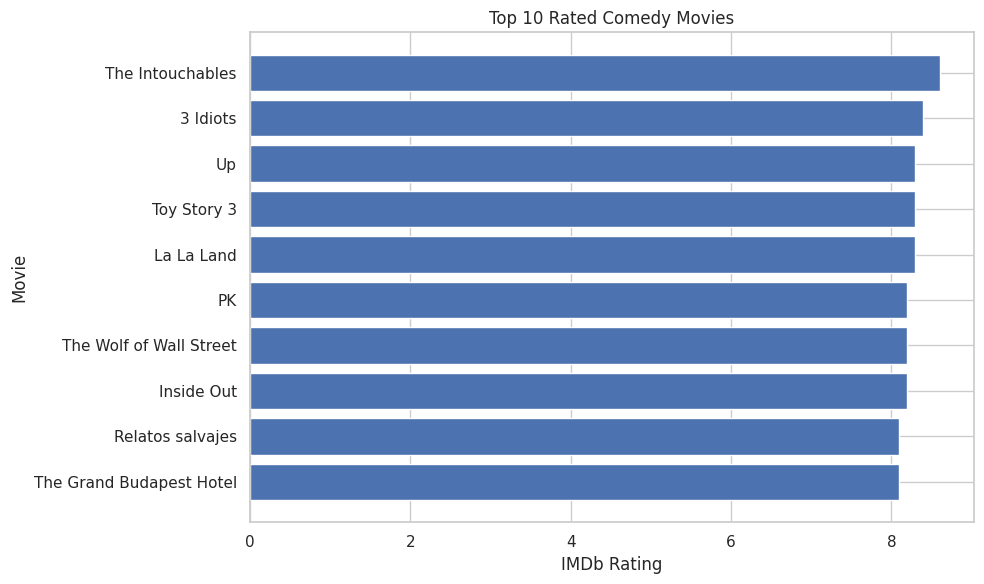

In [ ]:
plt.figure(figsize=(10,6))
plot_data = top10_comedy.sort_values('Rating')
plt.barh(plot_data['Title'], plot_data['Rating'])
plt.xlabel('IMDb Rating')
plt.ylabel('Movie')
plt.title('Top 10 Rated Comedy Movies')
plt.tight_layout()
plt.show()


## 6. Top 10 Movies by Revenue


In [ ]:
revenue_data = data.dropna(subset=['Revenue (Millions)']).sort_values('Revenue (Millions)', ascending=False)
top10_revenue = revenue_data[['Title','Revenue (Millions)','Rating','Year','Genre']].head(10)
display(top10_revenue.reset_index(drop=True))


,Title,Revenue (Millions),Rating,Year,Genre
0,Star Wars: Episode VII - The Force Awakens,936.63,8.1,2015,"Action,Adventure,Fantasy"
1,Avatar,760.51,7.8,2009,"Action,Adventure,Fantasy"
2,Jurassic World,652.18,7.0,2015,"Action,Adventure,Sci-Fi"
3,The Avengers,623.28,8.1,2012,"Action,Sci-Fi"
4,The Dark Knight,533.32,9.0,2008,"Action,Crime,Drama"
5,Rogue One,532.17,7.9,2016,"Action,Adventure,Sci-Fi"
6,Finding Dory,486.29,7.4,2016,"Animation,Adventure,Comedy"
7,Avengers: Age of Ultron,458.99,7.4,2015,"Action,Adventure,Sci-Fi"
8,The Dark Knight Rises,448.13,8.5,2012,"Action,Thriller"
9,The Hunger Games: Catching Fire,424.65,7.6,2013,"Action,Adventure,Mystery"


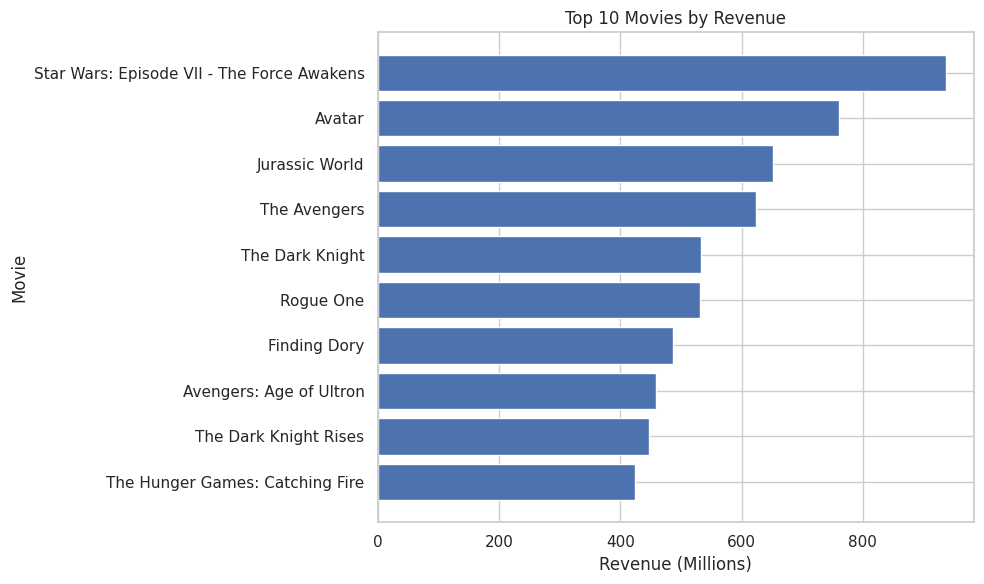

In [ ]:
plt.figure(figsize=(10,6))
plot_data = top10_revenue.sort_values('Revenue (Millions)')
plt.barh(plot_data['Title'], plot_data['Revenue (Millions)'])
plt.xlabel('Revenue (Millions)')
plt.ylabel('Movie')
plt.title('Top 10 Movies by Revenue')
plt.tight_layout()
plt.show()


## 7. Number of Movies Released Each Year


,Number of Movies
Year,
2006,44
2007,53
2008,52
2009,51
2010,60
2011,63
2012,64
2013,91
2014,98


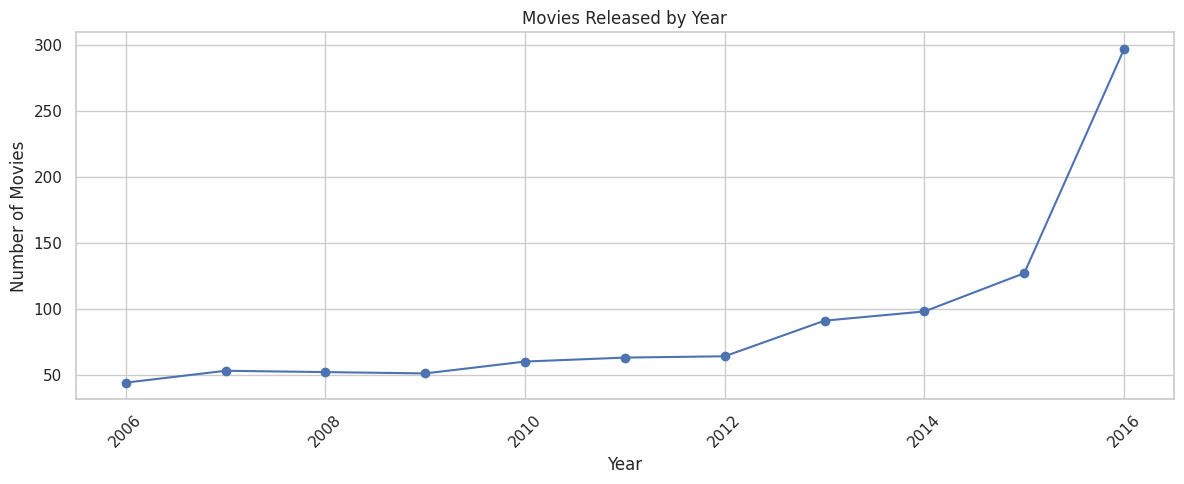

In [ ]:
year_counts = data.groupby('Year').size().sort_index()
display(year_counts.rename('Number of Movies').to_frame().tail(15))

plt.figure(figsize=(12,5))
plt.plot(year_counts.index, year_counts.values, marker='o')
plt.xlabel('Year')
plt.ylabel('Number of Movies')
plt.title('Movies Released by Year')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 8. Average Rating by Year


,Average Rating
Year,
2006,7.125000
2007,7.133962
2008,6.784615
2009,6.960784
2010,6.826667
2011,6.838095
2012,6.925000
2013,6.812088
2014,6.837755


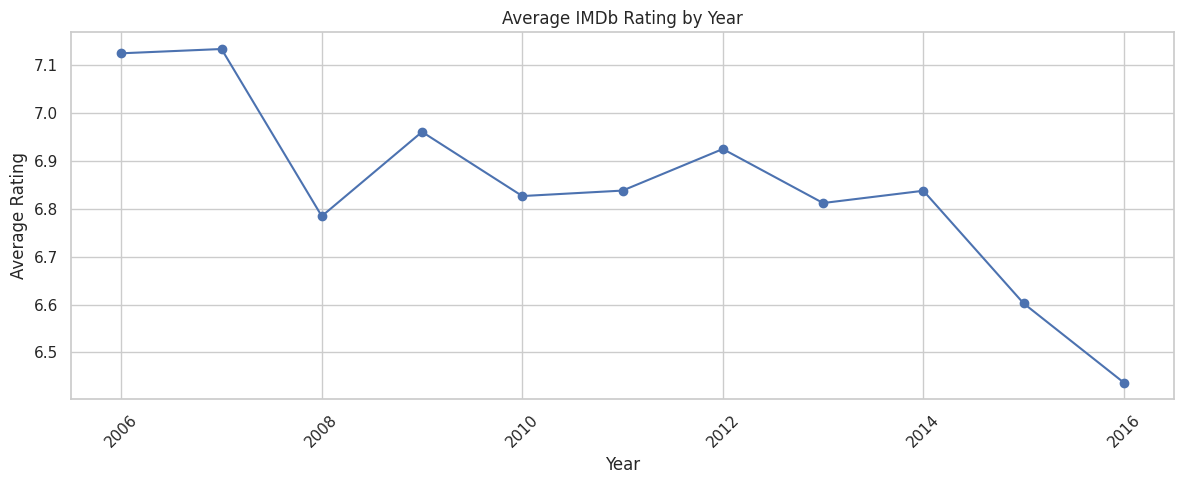

In [ ]:
avg_rating_year = data.groupby('Year')['Rating'].mean().sort_index()
display(avg_rating_year.tail(15).rename('Average Rating').to_frame())

plt.figure(figsize=(12,5))
plt.plot(avg_rating_year.index, avg_rating_year.values, marker='o')
plt.xlabel('Year')
plt.ylabel('Average Rating')
plt.title('Average IMDb Rating by Year')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 9. Average Rating of Major Genres


In [ ]:
genres = ['Action','Adventure','Animation','Comedy','Crime','Drama','Horror','Romance','Sci-Fi','Thriller']
genre_results = []
for genre in genres:
    subset = data[data['Genre'].str.contains(genre, case=False, na=False)]
    genre_results.append([genre, len(subset), subset['Rating'].mean()])

genre_summary = pd.DataFrame(genre_results, columns=['Genre','Movie Count','Average Rating']).sort_values('Average Rating', ascending=False)
display(genre_summary.reset_index(drop=True))


,Genre,Movie Count,Average Rating
0,Animation,49,7.324490
1,Drama,513,6.953801
2,Crime,150,6.786667
3,Adventure,259,6.772201
4,Sci-Fi,120,6.716667
5,Romance,141,6.685816
6,Comedy,279,6.647670
7,Action,303,6.614521
8,Thriller,195,6.593333
9,Horror,119,6.089916


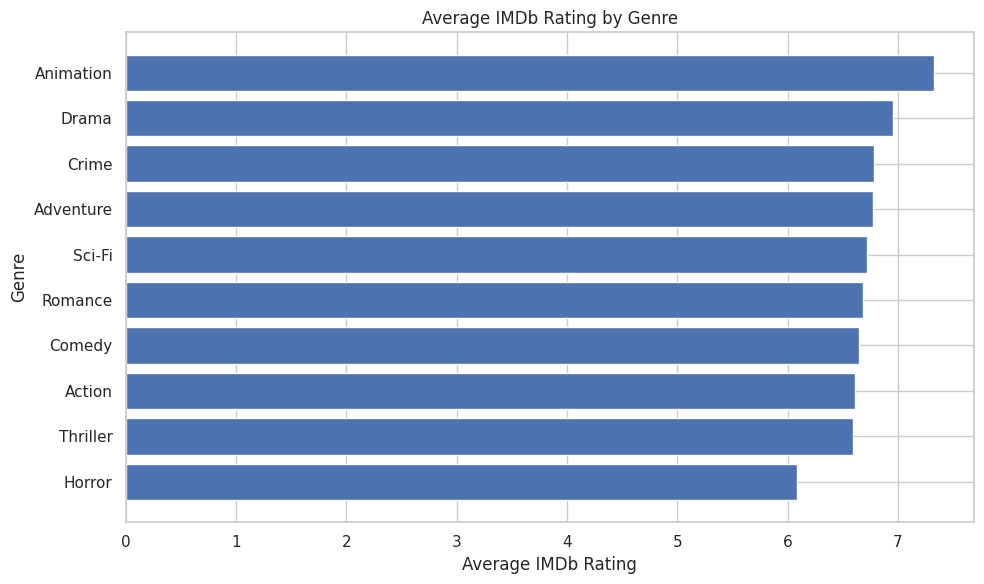

In [ ]:
plt.figure(figsize=(10,6))
plot_data = genre_summary.sort_values('Average Rating')
plt.barh(plot_data['Genre'], plot_data['Average Rating'])
plt.xlabel('Average IMDb Rating')
plt.ylabel('Genre')
plt.title('Average IMDb Rating by Genre')
plt.tight_layout()
plt.show()


## 10. Average Runtime by Genre


In [ ]:
runtime_results = []
for genre in genres:
    subset = data[data['Genre'].str.contains(genre, case=False, na=False)]
    runtime_results.append([genre, subset['Runtime (Minutes)'].mean()])

runtime_summary = pd.DataFrame(runtime_results, columns=['Genre','Average Runtime']).sort_values('Average Runtime', ascending=False)
display(runtime_summary.reset_index(drop=True))


,Genre,Average Runtime
0,Adventure,117.698842
1,Action,116.739274
2,Drama,116.635478
3,Sci-Fi,116.391667
4,Crime,115.413333
5,Romance,113.007092
6,Thriller,111.769231
7,Comedy,105.899642
8,Horror,101.563025
9,Animation,98.142857


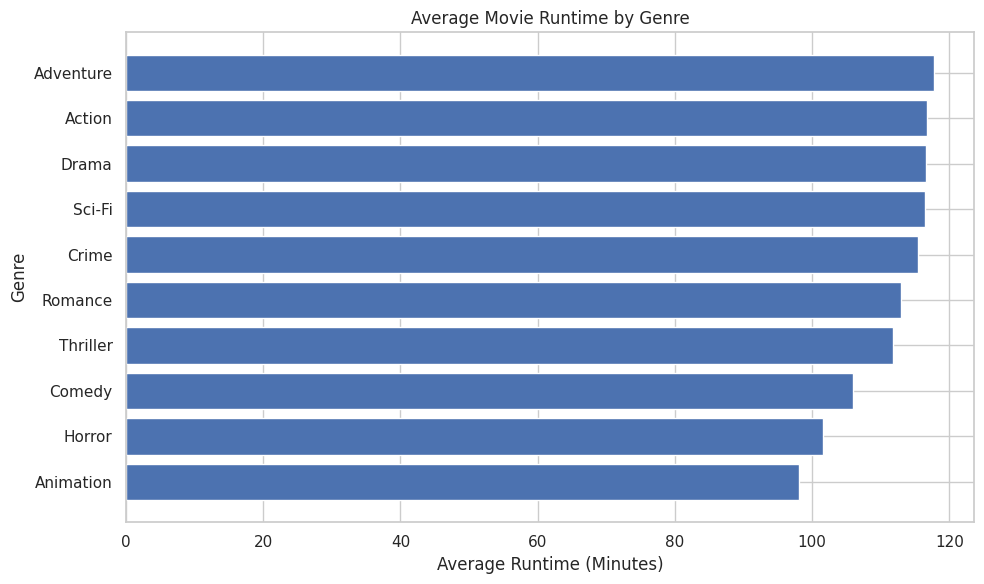

In [ ]:
plt.figure(figsize=(10,6))
plot_data = runtime_summary.sort_values('Average Runtime')
plt.barh(plot_data['Genre'], plot_data['Average Runtime'])
plt.xlabel('Average Runtime (Minutes)')
plt.ylabel('Genre')
plt.title('Average Movie Runtime by Genre')
plt.tight_layout()
plt.show()


## 11. Relationship Between Rating and Votes


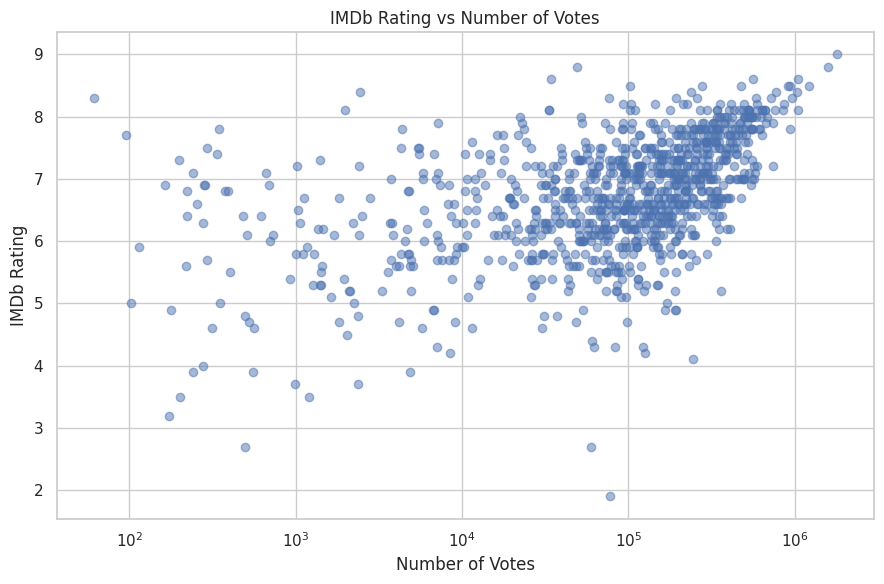

In [ ]:
plt.figure(figsize=(9,6))
plt.scatter(data['Votes'], data['Rating'], alpha=0.5)
plt.xlabel('Number of Votes')
plt.ylabel('IMDb Rating')
plt.title('IMDb Rating vs Number of Votes')
plt.xscale('log')
plt.tight_layout()
plt.show()


## 12. Key Findings


In [ ]:
print('PROJECT FINDINGS')
print('1. The notebook identifies the five highest-rated movies in the dataset.')
print('2. It identifies the ten highest-rated movies whose genre includes Comedy.')
print('3. It compares movies by revenue and visualizes the top revenue earners.')
print('4. It analyzes how the number of movies released changes by year.')
print('5. It compares average ratings and average runtime across major genres.')
print('6. It visualizes the relationship between IMDb ratings and the number of votes.')


PROJECT FINDINGS
1. The notebook identifies the five highest-rated movies in the dataset.
2. It identifies the ten highest-rated movies whose genre includes Comedy.
3. It compares movies by revenue and visualizes the top revenue earners.
4. It analyzes how the number of movies released changes by year.
5. It compares average ratings and average runtime across major genres.
6. It visualizes the relationship between IMDb ratings and the number of votes.


## 13. Conclusion
This project demonstrates how Python can be used to load, clean, analyze and visualize movie data. Pandas is used for data manipulation and grouping, while Matplotlib and Seaborn are used for visualization. The additional analyses extend the original project by answering specific questions about highly rated movies, Comedy movies, revenue, release years, genre ratings and runtime.